# Settings

In [216]:
#Simulation settings
using_simulation_data = True
parameters_file_path = "./parameters/003_simulation_test.json"

#Real data settings
imported_rf_matrix_delay_unit = "us"
using_matlab_data = True
matlab_rf_data_path = "C:/Users/Acer/Documents/UrbanLab/002_Superresolution/dataMatthieu/_FUS_131148/rf0.mat"
interpolate_data = True

#Beamforming settings
run_nsi_apodization = True
nsi_dc_offset = 0.1
other_apodization = "rectangle".lower()

save_data = True
beamformed_apodized_matrix_name = "003_2obj_1pitch_7angle"

# Imports

In [217]:
import numpy as np
import matplotlib.pyplot as plt
import json
from numba import njit
from scipy.signal import envelope, firwin
from scipy.io import loadmat

# Import parameters

In [218]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [196]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"] 

    return params

In [197]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.010008000000000001 m


# Import RF matrix

In [198]:
if using_simulation_data:

    rf_matrix_path = "./data/csv/rf_data/rf_matrix_summed.npy"

    rf_matrix_summed = np.load(rf_matrix_path)
    print("Imported RF matrix with shape: ", rf_matrix_summed.shape)

else:
    if using_matlab_data:
        rf_matrix_summed = loadmat(matlab_rf_data_path)
        rf_matrix_summed = list(rf_matrix_summed.values())[-1]
        rf_matrix_summed = np.float64(rf_matrix_summed)
        print("Imported RF matrix with shape: ", rf_matrix_summed.shape)

    match imported_rf_matrix_delay_unit.lower():
        case "s":
            rf_matrix_summed = rf_matrix_summed
            print("Delay unit is in seconds")
        case "ms":
            rf_matrix_summed = rf_matrix_summed * 1e-3
            print("Delay unit is in milliseconds, converting to seconds")
        case "us":
            rf_matrix_summed = rf_matrix_summed * 1e-6
            print("Delay unit is in microseconds, converting to seconds")
        case "ns":
            rf_matrix_summed = rf_matrix_summed * 1e-9
            print("Delay unit is in nanoseconds, converting to seconds")
        case _:
            rf_matrix_summed = rf_matrix_summed
            print("Unknown delay unit, please check the imported delay unit")

if interpolate_data:
    samples = params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["upsampled_sampling_rate"]
else:
    samples = params["rf"]["samples"]
    sampling_rate = params["rf"]["sampling_rate"]


Imported RF matrix with shape:  (834, 128, 7)


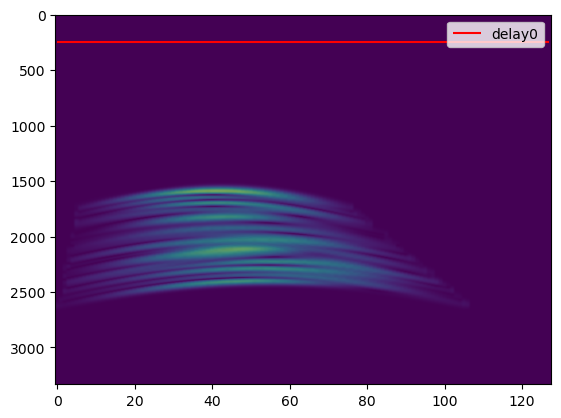

In [219]:
plt.imshow(np.abs(rf_matrix_summed[:,:,0]), aspect='auto', cmap='viridis')
plt.hlines(y=int(params["rf"]["delay0"] * params["rf"]["sampling_rate"]), xmin=0, xmax=rf_matrix_summed.shape[1]-1, color='red', label='delay0')
plt.legend()
plt.show()

# Interpolation

In [200]:
def zero_stuffing(rf_matrices_summed, interpolation_factor, upsampled_samples):
    interpolation_factor = interpolation_factor - 1
    
    new_matrices_summed = np.zeros((upsampled_samples, rf_matrices_summed.shape[1], rf_matrices_summed.shape[2]))
    
    for i in range(rf_matrices_summed.shape[2]): #for each angle
        for j in range(rf_matrices_summed.shape[1]): #for each transducer
            for k in range(rf_matrices_summed.shape[0]): #for each sample
                idx_new = k + (interpolation_factor * k)
                new_matrices_summed[idx_new, j, i] = rf_matrices_summed[k, j, i]

    return new_matrices_summed

In [201]:
def get_filtered_matrices(zero_stuffed_rf_matrices_summed, frequency, sampling_frequency):
    filtered_rf_matrices_summed = np.zeros((zero_stuffed_rf_matrices_summed.shape[0], zero_stuffed_rf_matrices_summed.shape[1], zero_stuffed_rf_matrices_summed.shape[2]))

    new_samples = zero_stuffed_rf_matrices_summed.shape[0]
    cutoff_freq = 0.50 * frequency #use Nyquist frequency as cutoff frequency
    
    filtering_function = firwin(new_samples, cutoff_freq, fs=sampling_frequency)

    for i in range(0, zero_stuffed_rf_matrices_summed.shape[2]): #for each angle
        for j in range(0, zero_stuffed_rf_matrices_summed.shape[1]): #for each transducer
            filtered_rf_matrices_summed[:,j,i] = np.convolve(zero_stuffed_rf_matrices_summed[:,j,i], filtering_function, mode='same')

    return filtered_rf_matrices_summed

Upsampled RF matrix with shape:  (3333, 128, 7)
Delay value  4e-06 is at index 1000


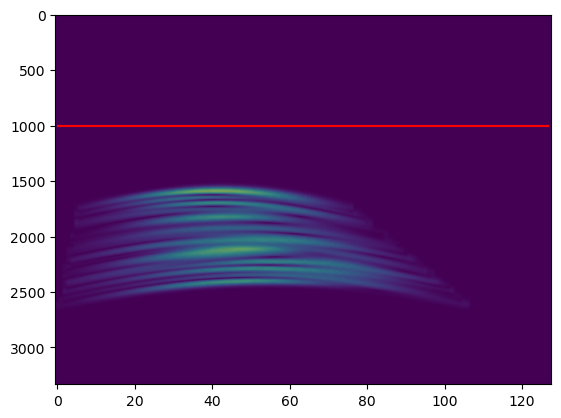

In [202]:
if interpolate_data:
    temp_zero_stuffed = zero_stuffing(rf_matrix_summed, params["rf"]["interpolation_factor"], params["rf"]["upsampled_samples"])
    rf_matrix_summed = get_filtered_matrices(temp_zero_stuffed, params["rf"]["frequency"], params["rf"]["sampling_rate"])
    
    print("Upsampled RF matrix with shape: ", rf_matrix_summed.shape)
    plt.imshow(np.abs(rf_matrix_summed[:,:,0]), aspect='auto', cmap='viridis')
    plt.hlines(y=int(params["rf"]["delay0"] * sampling_rate), xmin=0, xmax=rf_matrix_summed.shape[1]-1, color='red')
    print(f"Delay value  {params["rf"]["delay0"]} is at index {int(params["rf"]["delay0"] * sampling_rate)}")
    del temp_zero_stuffed

# Effective aperture

In [203]:
@njit()
def find_object_effective_aperture(current_position, current_depth, aperture, array_length, pitch):
    effective_array_length =  current_depth / aperture
    first_transducer = -1
    transducers_in_effective_array = 0
    
    for j in range(0, array_length):
        if j*pitch >= current_position - effective_array_length / 2 and j*pitch <= current_position + effective_array_length / 2:
            if first_transducer == -1:
                first_transducer = j
            transducers_in_effective_array += 1
    
    return effective_array_length, transducers_in_effective_array, first_transducer   
        

# Apodization

## Apodization functions

In [204]:
@njit()
def generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False):
    result = np.zeros(array_length) + offset
    
    for transducer_idx in range(array_length):
        if transducer_idx - first_transducer >= 0:  # making sure we are in the effective array range
            transducer_relative_idx = transducer_idx - first_transducer
            if 0 <= transducer_relative_idx < transducers_in_effective_array / 2:
                result[transducer_idx] = (-1 if mirror else 1) + offset
            elif transducers_in_effective_array / 2 <= transducer_relative_idx < transducers_in_effective_array:
                result[transducer_idx] = (1 if mirror else -1) + offset

    return result

@njit()
def generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0):
    result = np.zeros(array_length) + offset
    
    half_array = effective_array_length / 2
    amount_trimmed = (1 - amount_kept) * half_array
    
    for transducer_idx in range(array_length):
        position = transducer_idx * pitch
        lower_bound = current_position - half_array + amount_trimmed
        upper_bound = current_position + half_array - amount_trimmed
        
        if lower_bound <= position <= upper_bound:
            result[transducer_idx] = 1 + offset
        else:
            result[transducer_idx] = 0 + offset
    
    return result

In [205]:
@njit()
def apodization_wrapper(apodization_function, first_transducer, transducers_in_effective_array, effective_array_length, array_length, current_position, amount_kept, pitch, offset=0, mirror=False):
    
    match apodization_function:
        case "zm":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=0, mirror=False)
        case "dc1":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=nsi_dc_offset, mirror=False)
        case "dc2":
            return generate_zm_apodization(first_transducer, transducers_in_effective_array, array_length, offset=nsi_dc_offset, mirror=True)
        case "rectangle":
            return generate_rectangle_apodization(current_position, effective_array_length, array_length, amount_kept, pitch, offset=0)
        case _:
            return np.ones(array_length)

Effective array length:  0.005000197722239797 first_transducer:  23 transducers_in_effective_array:  55


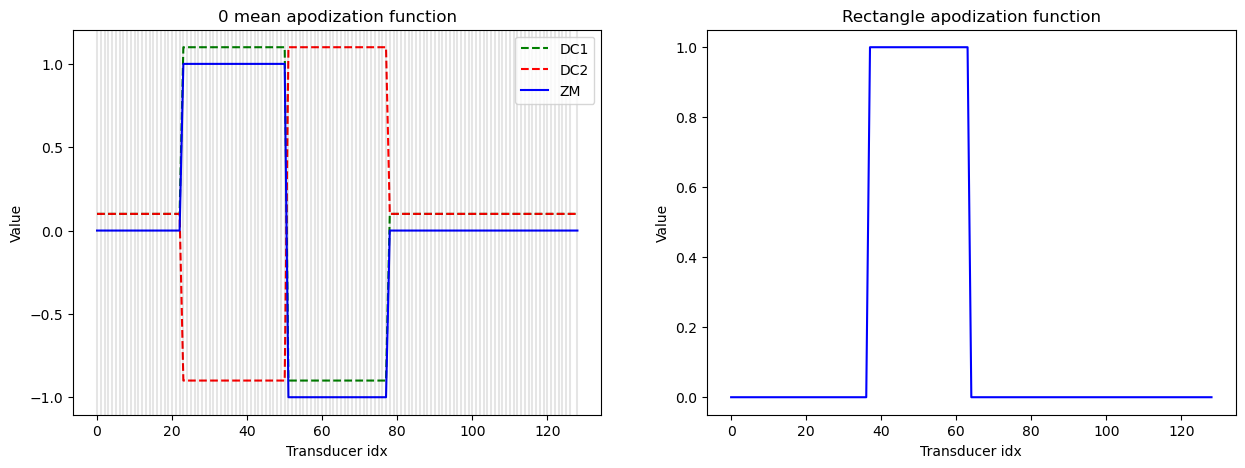

In [206]:
effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(200*2.25e-5, 1331*0.0095/3161, params["array"]["aperture"], params["array"]['length'], params["array"]["pitch"])
print("Effective array length: ", effective_array_length, "first_transducer: ", first_transducer, "transducers_in_effective_array: ", transducers_in_effective_array)

apodization_zm = apodization_wrapper("zm", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])
apodization_dc1 = apodization_wrapper("dc1", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])
apodization_dc2 = apodization_wrapper("dc2", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])
apodization_rectangle = apodization_wrapper("rectangle", first_transducer, transducers_in_effective_array, effective_array_length, params["array"]["length"], 200*2.25e-5, 0.5, params["array"]["pitch"])

fig, ax = plt.subplots(1,2, figsize=(15, 5))

ax[0].plot(pos, apodization_dc1, color='g', ls='--', label='DC1')
ax[0].plot(pos, apodization_dc2, color='r', ls='--', label ='DC2')
ax[0].plot(pos, apodization_zm, color='b', label='ZM')
for x in pos:
    ax[0].axvline(x=x, color='black', ls='-', alpha=0.1)
ax[0].set_title('0 mean apodization function')
ax[0].set_xlabel('Transducer idx')
ax[0].set_ylabel('Value')
ax[0].legend()

ax[1].plot(pos, apodization_rectangle, color='b')
ax[1].set_title('Rectangle apodization function')
ax[1].set_xlabel('Transducer idx')
ax[1].set_ylabel('Value')
plt.show()

# Beamforming

In [207]:
def save_beamformed_data(bf_matrix, filename, destination="./data_nsi/csv/beamformed/"):
    np.save(f"{destination}{filename}", bf_matrix)
    print(f"Beamformed data saved at: {destination}{filename}.npy")

In [208]:
@njit(parallel=True)
def beamforming_opt(rf_summed_matrices, nx, nz, dx, dz, x0, z0, delay0, pitch, c, array_length, samples, sampling_rate, aperture, apodization_function, using_real_data, angles = [0]):

    max_acquisition_depth = c * (1 / sampling_rate * samples) / 2
    samples_for_acquisition_depth = int(max_acquisition_depth / dz)
    samples_for_array_length = int(array_length * pitch / dx)

    bf_matrix = np.zeros((samples_for_acquisition_depth, samples_for_array_length, len(angles)))

    if nx is None:
        nx = samples_for_array_length
    if nz is None:
        nz = samples_for_acquisition_depth

    print("\n" + "="*60)
    print(f"✓ BEAMFORMING CONFIGURATION:")
    print(f"  • Resolution: {nx} x {nz}")
    print(f"  • Acquisition depth:",max_acquisition_depth,"m",f"({samples_for_acquisition_depth} samples)")
    print(f"  • Array length:",array_length * pitch,"m",f"({samples_for_array_length} samples)")
    print(f"  • Apodization: {apodization_function}")
    print(f"  • Processing {len(angles)} angle(s)")
    print("-"*60)
    
    for i in range(0, len(angles)): #for each angle
        print(f"  ↳ Processing angle",angles[i],"°",f"[{i+1}/{len(angles)}]")

        cos_angle = np.cos(angles[i] * np.pi/180)
        sin_angle = np.sin(angles[i] * np.pi/180)

        additional_delay = 0
        
        if angles[i] < 0 and using_real_data:
            additional_delay = (array_length * pitch) * sin_angle / c
        
        for j in range(0, samples_for_array_length): #for each lateral res sample

            if j < x0 or j > x0 + nx:
                continue

            for k in range(0, samples_for_acquisition_depth): #for vertical res sample

                if k < z0 or k > z0 + nz:
                    continue

                depth = dz*k
                position = dx*j

                effective_array_length, transducers_in_effective_array, first_transducer = find_object_effective_aperture(position, depth, aperture, array_length, pitch)

                apodization = apodization_wrapper(
                    apodization_function, 
                    first_transducer, 
                    transducers_in_effective_array, 
                    effective_array_length, 
                    array_length, 
                    position, 
                    0.5, 
                    pitch
                )

                for l in range(0, array_length): #for each transducer
                    delay = ((depth * cos_angle + position * sin_angle) / c)  + (np.sqrt(depth**2 + (l * pitch - position)**2) / c) - additional_delay
                    delay_idx = int(delay * sampling_rate) #delay in s * sampling rate in 1/s = delay in samples (number of samples to reach delay)
                    if delay_idx < samples and delay >= delay0:
                        bf_matrix[k,j,i] += rf_summed_matrices[delay_idx, l, i] * apodization[l] #we use previously computed values for better perf

    print("-"*60)
    print(f"✓ BEAMFORMING COMPLETE")
    print(f"  • Output shape: ", bf_matrix.shape)
    print("="*60 + "\n")
    return bf_matrix

In [209]:
bf_nsi_matrices = []

nsi_apo_funcs = ["zm", "dc1", "dc2"]

if run_nsi_apodization:
    print("Running NSI apodizations")
    for apo_func in nsi_apo_funcs:
        bf_apodized_matrix = beamforming_opt(
            rf_matrix_summed, 
            params["image"]["nx"], 
            params["image"]["nz"],
            params["image"]["dx"],
            params["image"]["dz"],
            params["image"]["x0"],
            params["image"]["z0"],
            params["rf"]["delay0"],
            params["array"]["pitch"], 
            C, 
            params["array"]["length"], 
            samples,
            sampling_rate, 
            params["array"]["aperture"],
            apo_func,
            not using_simulation_data,
            angles= params["rf"]["angles"]
        )
        bf_nsi_matrices.append(bf_apodized_matrix)
        if save_data:
            save_beamformed_data(bf_apodized_matrix, f"{beamformed_apodized_matrix_name}_{apo_func}", destination="./data_nsi/csv/beamformed_apodizations/")

else :
    print(f"Running {other_apodization} apodization")
    bf_apodized_matrix = beamforming_opt(
        rf_matrix_summed, 
        params["image"]["nx"], 
        params["image"]["nz"],
        params["image"]["dx"],
        params["image"]["dz"],
        params["image"]["x0"],
        params["image"]["z0"],
        params["rf"]["delay0"],
        params["array"]["pitch"], 
        C, 
        params["array"]["length"], 
        samples,
        sampling_rate, 
        params["array"]["aperture"],
        other_apodization,
        not using_simulation_data,
        angles= params["rf"]["angles"]
    )
    if save_data:
        save_beamformed_data(bf_apodized_matrix, f"{beamformed_apodized_matrix_name}_{other_apodization}", destination="./data_nsi/csv/beamformed_apodizations/")    

Running NSI apodizations

✓ BEAMFORMING CONFIGURATION:
  • Resolution: 1024 x 888
  • Acquisition depth: 0.009999000000000001 m (888 samples)
  • Array length: 0.01152 m (1024 samples)
  • Apodization: zm
  • Processing 7 angle(s)
------------------------------------------------------------
  ↳ Processing angle -9.0 ° [1/7]
  ↳ Processing angle -6.0 ° [2/7]
  ↳ Processing angle -3.0 ° [3/7]
  ↳ Processing angle 0.0 ° [4/7]
  ↳ Processing angle 3.0 ° [5/7]
  ↳ Processing angle 6.0 ° [6/7]
  ↳ Processing angle 9.0 ° [7/7]
------------------------------------------------------------
✓ BEAMFORMING COMPLETE
  • Output shape:  (888, 1024, 7)

Beamformed data saved at: ./data_nsi/csv/beamformed_apodizations/003_2obj_1pitch_7angle_zm.npy

✓ BEAMFORMING CONFIGURATION:
  • Resolution: 1024 x 888
  • Acquisition depth: 0.009999000000000001 m (888 samples)
  • Array length: 0.01152 m (1024 samples)
  • Apodization: dc1
  • Processing 7 angle(s)
-----------------------------------------------------

## Load saved matricies

In [210]:
bf_apodized_matrices_loaded = []

if run_nsi_apodization:
    for apo_func in nsi_apo_funcs:
        bf_apodized_matrices_loaded.append(np.load(f"./data_nsi/csv/beamformed_apodizations/{beamformed_apodized_matrix_name}_{apo_func}.npy"))
else :
    bf_apodized_matrices_loaded.append(np.load(f"./data_nsi/csv/beamformed_apodizations/{beamformed_apodized_matrix_name}_{other_apodization}.npy"))

In [211]:
bf_apodized_matrices_summed = [np.sum(bf_apodized_matrices_loaded, axis=2) for bf_apodized_matrices_loaded in bf_apodized_matrices_loaded]

## Envelopes

In [212]:
def get_envelope(bf_matrix):

    lateral_resolution = bf_matrix.shape[1]
    samples = bf_matrix.shape[0]

    env = np.zeros((samples, lateral_resolution))
    for i in range(0, lateral_resolution):
        env[:, i] = envelope(bf_matrix[:, i], residual=None)
    return env

In [213]:
if run_nsi_apodization:
    bf_matrix_zm = bf_apodized_matrices_summed[0]
    bf_matrix_dc1 = bf_apodized_matrices_summed[1]
    bf_matrix_dc2 = bf_apodized_matrices_summed[2]

    env_zm = get_envelope(bf_matrix_zm)
    env_dc1 = get_envelope(bf_matrix_dc1)
    env_dc2 = get_envelope(bf_matrix_dc2)
else:
    bf_matrix_apo = bf_apodized_matrices_summed[0]

## Average offsets and sum

In [214]:
if run_nsi_apodization:
    env_nsi = (env_dc1 + env_dc2) / 2 - env_zm
    if save_data:
        save_beamformed_data(env_nsi, f"{beamformed_apodized_matrix_name}_env_nsi")
else:
    if save_data:
        save_beamformed_data(bf_matrix_apo, f"{beamformed_apodized_matrix_name}_{other_apodization}")

Beamformed data saved at: ./data_nsi/csv/beamformed/003_2obj_1pitch_7angle_env_nsi.npy


## Show beamformed image

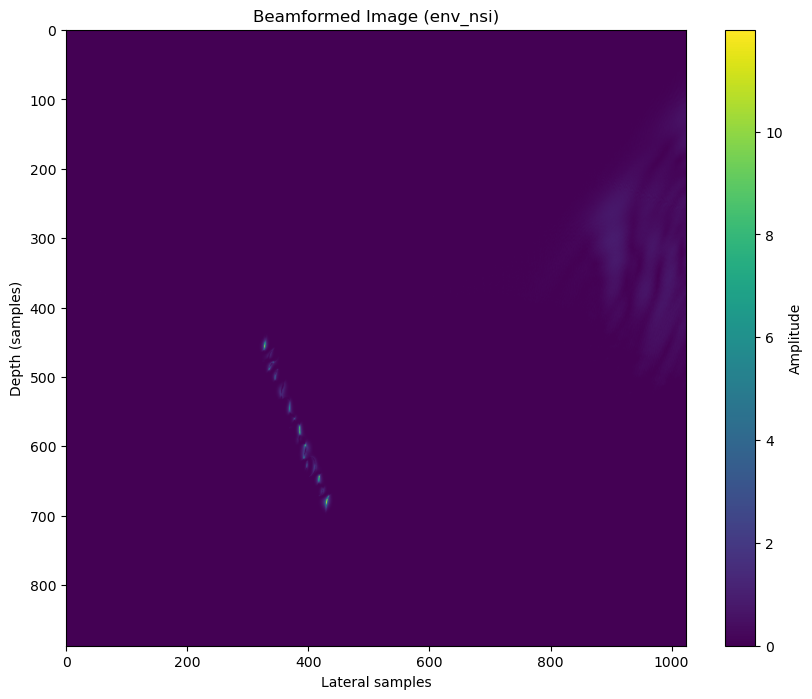

In [215]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(env_nsi if run_nsi_apodization else bf_matrix_apo), cmap='viridis', aspect='auto')
plt.title(f"Beamformed Image ({'env_nsi' if run_nsi_apodization else other_apodization})")
plt.xlabel("Lateral samples")
plt.ylabel("Depth (samples)")

#box around the xo, zo, nx, nz
x0 = params["image"]["x0"]
z0 = params["image"]["z0"]
nx = params["image"]["nx"]
nz = params["image"]["nz"]

if nx is not None and nz is not None:
    plt.plot([x0, x0+nx, x0+nx, x0, x0], [z0, z0, z0+nz, z0+nz, z0], 'r--', label='ROI')
    plt.legend()

plt.colorbar(label="Amplitude") 

if save_data:
    plt.savefig(f"./data_nsi/images/{beamformed_apodized_matrix_name}_{"env_nsi" if run_nsi_apodization else other_apodization}.png")
plt.show()